# AI for Bio · A high-accuracy result can still be wrong

**Featured debugging example:** Repeated observations from the same simulated participant can introduce identity leakage into machine-learning evaluation.

This demonstration uses **fully synthetic measurements, not patient records**. Labels are sampled independently of the underlying features, so no generalizable biological association exists.

**Question:** Does a nearest-neighbor classifier learn a transferable mapping, or does it memorize participant identity?

Learning goals:
1. Explain why repeated observations need grouped evaluation.
2. Compare random-sample and participant-held-out test sets.
3. Document a failure mechanism and a correction.
4. Distinguish predictive success from scientifically valid evidence.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

SEED = 42
N_PARTICIPANTS = 300
MEASUREMENTS_PER_PARTICIPANT = 6
rng = np.random.default_rng(SEED)

# Each participant has a distinct stable fingerprint (nuisance feature).
# Labels are random at the participant level: there is no biological signal to learn.
participant_labels = rng.integers(0, 2, size=N_PARTICIPANTS)
participant_fingerprints = rng.normal(0, 1, size=(N_PARTICIPANTS, 12))
participant_ids = np.repeat(np.arange(N_PARTICIPANTS), MEASUREMENTS_PER_PARTICIPANT)
X = np.repeat(participant_fingerprints, MEASUREMENTS_PER_PARTICIPANT, axis=0)
X += rng.normal(0, 0.04, size=X.shape)  # small measurement variation
y = np.repeat(participant_labels, MEASUREMENTS_PER_PARTICIPANT)
print('Measurements:', X.shape, 'Participants:', len(np.unique(participant_ids)))

Measurements: (1800, 12) Participants: 300


In [2]:
# Split individual readings at random. The same participant can appear in both partitions.
train_random, test_random = train_test_split(
    np.arange(len(y)), test_size=0.25, random_state=SEED, stratify=y
)
model_random = KNeighborsClassifier(n_neighbors=1).fit(X[train_random], y[train_random])
accuracy_random = accuracy_score(y[test_random], model_random.predict(X[test_random]))
overlap_random = len(set(participant_ids[train_random]) & set(participant_ids[test_random]))

# Split by participants. No participant can appear in both partitions.
group_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_group, test_group = next(group_split.split(X, y, participant_ids))
model_group = KNeighborsClassifier(n_neighbors=1).fit(X[train_group], y[train_group])
accuracy_group = accuracy_score(y[test_group], model_group.predict(X[test_group]))
overlap_group = len(set(participant_ids[train_group]) & set(participant_ids[test_group]))

print(f'Random sample split:       {accuracy_random:.1%} accuracy | {overlap_random} overlapping participants')
print(f'Participant-held-out split:{accuracy_group:>7.1%} accuracy | {overlap_group} overlapping participants')
assert overlap_group == 0
assert accuracy_random > 0.9
assert 0.2 < accuracy_group < 0.8

Random sample split:       100.0% accuracy | 250 overlapping participants
Participant-held-out split:  47.3% accuracy | 0 overlapping participants


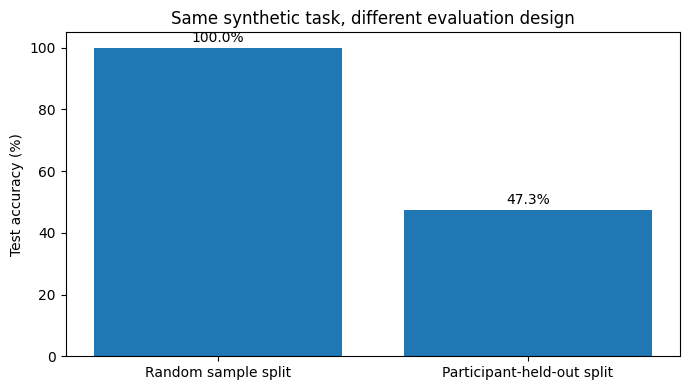

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Random sample split', 'Participant-held-out split'],
              [accuracy_random * 100, accuracy_group * 100])
ax.set_ylabel('Test accuracy (%)')
ax.set_ylim(0, 105)
for rect, acc in zip(bars, [accuracy_random, accuracy_group]):
    ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 2,
            f'{acc:.1%}', ha='center')
ax.set_title('Same synthetic task, different evaluation design')
fig.tight_layout()
plt.show()

## Why this matters

The random split lets the classifier exploit a **participant fingerprint** shared by training and test readings. Its apparent accuracy is excellent even though the label is randomly assigned and has no transferable relation to the features.

The participant-held-out split measures generalization to unseen simulated participants. Its accuracy is near chance in this particular fixed-seed run. An estimate below or above 50% is possible because the task has random labels and finite sample size.

**This does not imply that all random sample splits are invalid.** It illustrates why the unit of independence must follow the intended claim and acquisition protocol. If the claim concerns new participants, then new participants should be held out.

### Suggested debugging dossier

- State the scientific claim and correct unit of analysis.
- Include a participant overlap check and explicit split manifest.
- Show the before/after result and identify the shortcut.
- Explain why retuning the classifier would not repair the evaluation design.
- Describe a follow-up using genuine biomedical measurements and legitimate participant-level folds.

**Limits:** This synthetic example is purpose-built to show identity leakage. It is not a clinical result, a realistic estimate of ECG/EMG model performance, or an observed student learning outcome.